## 1. Imports and project paths

Only `pandas` and `matplotlib` are required beyond the Python standard library. We resolve the repository root from the current notebook working directory, rather than hardcoding the author's Windows path.

In [11]:
from pathlib import Path
import json
import re
import unicodedata
import hashlib
from collections import Counter, defaultdict
from copy import deepcopy

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SOURCE_FILES = ["corpus.jsonl", "claims_train.jsonl", "claims_dev.jsonl", "claims_test.jsonl"]

def locate_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        raw_dir = candidate / "data" / "scifact"
        if all((raw_dir / name).is_file() for name in SOURCE_FILES):
            return candidate
    raise FileNotFoundError(
        "Cannot find data/scifact/ with all four SciFact files. "
        "Save this notebook in LitScope-Lite/notebooks/ and open it from that project."
    )

ROOT = locate_project_root()
RAW_DIR = ROOT / "data" / "scifact"
PROCESSED_DIR = ROOT / "data" / "processed"
IMAGES_DIR = ROOT / "images"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("Raw data:", RAW_DIR)
print("Processed output:", PROCESSED_DIR)


Project root: C:\Users\muham\OneDrive\Desktop\ds_project\LitScope-Lite
Raw data: C:\Users\muham\OneDrive\Desktop\ds_project\LitScope-Lite\data\scifact
Processed output: C:\Users\muham\OneDrive\Desktop\ds_project\LitScope-Lite\data\processed


## 2. Load the original JSONL files

A malformed JSON line is a **hard error** because silently skipping records would compromise the dataset and potentially its evidence links. We retain the original records in memory without modifying the files on disk.

In [12]:
def load_jsonl(path):
    rows = []
    with path.open("r", encoding="utf-8-sig") as handle:
        for line_num, line in enumerate(handle, 1):
            if not line.strip():
                continue
            try:
                record = json.loads(line)
            except json.JSONDecodeError as err:
                raise ValueError(f"Invalid JSON in {path.name}, line {line_num}: {err}") from err
            if not isinstance(record, dict):
                raise TypeError(f"Expected object in {path.name}, line {line_num}")
            rows.append(record)
    return rows

original = {name: load_jsonl(RAW_DIR / name) for name in SOURCE_FILES}
corpus = original["corpus.jsonl"]
splits = {part: original[f"claims_{part}.jsonl"] for part in ("train", "dev", "test")}

inventory = pd.DataFrame([
    {"file": name, "records": len(records), "size_KiB": round((RAW_DIR / name).stat().st_size / 1024, 1)}
    for name, records in original.items()
])
display(inventory)
print("Total claims:", sum(len(rows) for rows in splits.values()))
print("Total abstract sentences:", sum(len(d["abstract"]) for d in corpus))


,file,records,size_KiB
0,corpus.jsonl,5183,8113.2
1,claims_train.jsonl,809,171.5
2,claims_dev.jsonl,300,63.5
3,claims_test.jsonl,300,33.0


Total claims: 1409
Total abstract sentences: 45952


## 3. Schema and missing-value checks

The unlabeled **test** records intentionally contain only `id` and `claim`; absence of `evidence` or `cited_doc_ids` on those records is **not** a missing-value error.

Required fields with invalid types, or text that is empty, should be reported and addressed, not filled with invented scientific claims.

In [13]:
required_corpus = {"doc_id", "title", "abstract", "structured"}
required_claims = {"id", "claim"}
required_labeled = {"evidence", "cited_doc_ids"}

issues = []

def issue(file, row, field, problem):
    issues.append({"file": file, "row_index": row, "field": field, "issue": problem})

for row_idx, doc in enumerate(corpus):
    if not required_corpus.issubset(doc):
        issue("corpus.jsonl", row_idx, "schema", "missing_required_key")
        continue
    if not isinstance(doc["doc_id"], int):
        issue("corpus.jsonl", row_idx, "doc_id", "invalid_type")
    if not isinstance(doc["title"], str) or not doc["title"].strip():
        issue("corpus.jsonl", row_idx, "title", "missing_or_empty")
    if not isinstance(doc["abstract"], list) or not doc["abstract"]:
        issue("corpus.jsonl", row_idx, "abstract", "missing_or_empty")
    elif any(not isinstance(s, str) or not s.strip() for s in doc["abstract"]):
        issue("corpus.jsonl", row_idx, "abstract", "empty_or_nonstring_sentence")
    if not isinstance(doc["structured"], bool):
        issue("corpus.jsonl", row_idx, "structured", "invalid_type")

for split, claims in splits.items():
    file = f"claims_{split}.jsonl"
    for row_idx, record in enumerate(claims):
        expected = required_claims | (required_labeled if split != "test" else set())
        if not expected.issubset(record):
            issue(file, row_idx, "schema", "missing_required_key")
            continue
        if not isinstance(record["id"], int):
            issue(file, row_idx, "id", "invalid_type")
        if not isinstance(record["claim"], str) or not record["claim"].strip():
            issue(file, row_idx, "claim", "missing_or_empty")
        if split != "test":
            if not isinstance(record["evidence"], dict):
                issue(file, row_idx, "evidence", "invalid_type")
            if not isinstance(record["cited_doc_ids"], list):
                issue(file, row_idx, "cited_doc_ids", "invalid_type")

issues_df = pd.DataFrame(issues, columns=["file", "row_index", "field", "issue"])
print("Missing/invalid required values:", len(issues_df))
if not issues_df.empty:
    display(issues_df.head(15))
    raise ValueError("Source contains invalid required data. Review these issues before continuing.")
print("No missing required values or malformed required field types detected.")


Missing/invalid required values: 0
No missing required values or malformed required field types detected.


## 4. IDs and evidence-reference integrity

We validate **before** cleaning: no duplicate document IDs, no duplicate claim IDs within a split, all annotated evidence document IDs exist, and every evidence sentence index is in bounds. All these properties must hold **again** after cleaning.

In [14]:
def validate_structure_and_evidence(files):
    docs = files["corpus.jsonl"]
    docs_by_id = {int(doc["doc_id"]): doc for doc in docs}
    errors = []
    if len(docs_by_id) != len(docs):
        errors.append("duplicate corpus doc_id")
    annotations = 0
    for split in ("train", "dev", "test"):
        rows = files[f"claims_{split}.jsonl"]
        if len({r["id"] for r in rows}) != len(rows):
            errors.append(f"duplicate claim id within {split}")
        if split == "test":
            continue
        for record in rows:
            cited = set(record["cited_doc_ids"])
            for docid in cited:
                if int(docid) not in docs_by_id:
                    errors.append(f"claim {record['id']}: cited doc {docid} missing")
            for docid_text, evidence_sets in record["evidence"].items():
                docid = int(docid_text)
                if docid not in docs_by_id:
                    errors.append(f"claim {record['id']}: evidence doc {docid} missing")
                    continue
                if docid not in cited:
                    errors.append(f"claim {record['id']}: evidence doc {docid} not cited")
                for evidence in evidence_sets:
                    annotations += 1
                    if evidence.get("label") not in {"SUPPORT", "CONTRADICT"}:
                        errors.append(f"claim {record['id']}: unexpected evidence label")
                    indices = evidence.get("sentences", [])
                    if not isinstance(indices, list) or not indices:
                        errors.append(f"claim {record['id']}: empty evidence indices")
                        continue
                    for index in indices:
                        if not isinstance(index, int) or index < 0 or index >= len(docs_by_id[docid]["abstract"]):
                            errors.append(f"claim {record['id']}: invalid evidence index {index} in doc {docid}")
    return {"document_ids": len(docs_by_id), "evidence_sets": annotations, "error_count": len(errors), "examples": errors[:10]}

before_integrity = validate_structure_and_evidence(original)
print(json.dumps(before_integrity, indent=2))
assert before_integrity["error_count"] == 0, before_integrity["examples"]


{
  "document_ids": 5183,
  "evidence_sets": 1295,
  "error_count": 0,
  "examples": []
}


## 5. Duplicate inventory (flag, do not delete)

We check duplicate document titles, repeated sentences **inside the same abstract**, duplicate claim texts within each split, and matching claim texts across splits. Identical text can still be a legitimate claim or evidence sentence; the presence of a duplicate alone is not a deletion rule.

**Critical:** Never remove or reorder a sentence from an abstract without updating all evidence index references.

In [15]:
def comparison_key(text):
    return " ".join(unicodedata.normalize("NFC", text).casefold().split())

dup_titles = Counter(comparison_key(doc["title"]) for doc in corpus)
duplicate_title_excess = sum(n - 1 for n in dup_titles.values() if n > 1)

sentence_duplicates = []
for doc in corpus:
    seen = {}
    for idx, sentence in enumerate(doc["abstract"]):
        key = comparison_key(sentence)
        if key in seen:
            sentence_duplicates.append({"doc_id": doc["doc_id"], "sentence_index": idx, "first_index": seen[key]})
        else:
            seen[key] = idx

claim_duplicates = []
claim_seen = defaultdict(list)
for split, rows in splits.items():
    for record in rows:
        claim_seen[comparison_key(record["claim"])].append((split, record["id"]))
for key, occurrences in claim_seen.items():
    if len(occurrences) > 1:
        involved = sorted(set(split for split, _ in occurrences))
        for split, claim_id in occurrences:
            claim_duplicates.append({
                "split": split, "claim_id": claim_id,
                "total_matching_claims": len(occurrences),
                "matches_across_splits": len(involved) > 1,
                "other_splits": ",".join(s for s in involved if s != split),
            })

dupe_report = pd.DataFrame([
    {"check": "Duplicate document IDs", "excess_occurrences": len(corpus) - len({d['doc_id'] for d in corpus})},
    {"check": "Duplicate normalized titles", "excess_occurrences": duplicate_title_excess},
    {"check": "Repeated sentences within abstracts", "excess_occurrences": len(sentence_duplicates)},
    {"check": "Claim texts duplicated within or across splits", "excess_occurrences": sum(len(v)-1 for v in claim_seen.values() if len(v)>1)},
])
display(dupe_report)
print("Documents with repeated sentences:", len({r["doc_id"] for r in sentence_duplicates}))
print("Claim text overlap cases:", sum(len(set(s for s, _ in occ)) > 1 for occ in claim_seen.values()))


,check,excess_occurrences
0,Duplicate document IDs,0
1,Duplicate normalized titles,3
2,Repeated sentences within abstracts,808
3,Claim texts duplicated within or across splits,8


Documents with repeated sentences: 13
Claim text overlap cases: 3


## 6. Safe text normalization

We apply just two non-destructive standardizations to **text strings**:

1. Unicode **NFC** normalization (retains scientific symbols and distinctions, unlike aggressive NFKC folding).
2. Replace runs of whitespace (including embedded tabs, newlines, and non-breaking spaces) with one regular space and trim outer whitespace.

We deliberately **do not** remove `<...>`-looking text: this dataset contains clinical comparator notation such as `</=5` and `<or=3` that would be mangled by a naive HTML-tag remover. We also **do not guess** what the replacement character `�` originally meant.

IDs, evidence dictionaries, cited document IDs, abstract sentence counts, sentence order, and split membership are unchanged.

In [16]:
def normalize_text(text):
    text = unicodedata.normalize("NFC", text)
    return re.sub(r"\s+", " ", text).strip()

# Note: the code above intentionally uses the ordinary regular-expression
# whitespace character class; no external text cleaners are needed.
changes = []
cleaned = deepcopy(original)

def replace_and_log(file, record_id, field, before, index=None):
    after = normalize_text(before)
    if after != before:
        changes.append({
            "file": file, "record_id": record_id, "field": field,
            "sentence_index": index,
            "original_preview": repr(before[:100]),
            "cleaned_preview": repr(after[:100]),
        })
    return after

for doc in cleaned["corpus.jsonl"]:
    doc["title"] = replace_and_log("corpus.jsonl", doc["doc_id"], "title", doc["title"])
    doc["abstract"] = [
        replace_and_log("corpus.jsonl", doc["doc_id"], "abstract_sentence", sentence, idx)
        for idx, sentence in enumerate(doc["abstract"])
    ]

for split in ("train", "dev", "test"):
    for record in cleaned[f"claims_{split}.jsonl"]:
        record["claim"] = replace_and_log(f"claims_{split}.jsonl", record["id"], "claim", record["claim"])

changes_df = pd.DataFrame(changes, columns=[
    "file", "record_id", "field", "sentence_index", "original_preview", "cleaned_preview"
])
print("Text strings normalized:", len(changes_df))
if not changes_df.empty:
    display(changes_df.groupby(["file", "field"]).size().rename("normalized_strings").reset_index())
    display(changes_df.head(6))


Text strings normalized: 3843


,file,field,normalized_strings
0,claims_dev.jsonl,claim,2
1,claims_test.jsonl,claim,4
2,claims_train.jsonl,claim,3
3,corpus.jsonl,abstract_sentence,3815
4,corpus.jsonl,title,19


,file,record_id,field,sentence_index,original_preview,cleaned_preview
0,corpus.jsonl,54440,abstract_sentence,2.0,'This microarray incorporated oligonucleotide ...,'This microarray incorporated oligonucleotide ...
1,corpus.jsonl,54440,abstract_sentence,6.0,'For each serotype combination with high proba...,'For each serotype combination with high proba...
2,corpus.jsonl,79447,abstract_sentence,0.0,'OBJECTIVE The purpose of this study was to ch...,'OBJECTIVE The purpose of this study was to ch...
3,corpus.jsonl,79447,abstract_sentence,6.0,'Visceral fat exhibited greater expression of ...,'Visceral fat exhibited greater expression of ...
4,corpus.jsonl,87758,abstract_sentence,1.0,'We compare CIMT and ABPI with atheroma burden...,'We compare CIMT and ABPI with atheroma burden...
5,corpus.jsonl,87758,abstract_sentence,6.0,'The segment scores were summed and from this ...,'The segment scores were summed and from this ...


## 7. Document and sentence quality flags

**Handling outliers:** We identify statistical extremes and source-extraction anomalies for review; we do **not** automatically delete them. Long scientific sentences may be valid, and very short entries may be meaningful headings or formula fragments. Truncation before model tokenization is a modeling choice for Phase 2, not a data-cleaning repair.

The 1.5×IQR upper fence is computed on the original corpus sentence lengths. We additionally flag very short sentences (1–2 words), repeated sentence entries, visible replacement characters, and very high within-document repetition. Thresholds are *diagnostic only*.

`document_quality_flags.csv` is an inspection table for **all** documents, with review flags; `sentence_quality_flags.csv` holds only sentences with at least one flag.

In [17]:
def word_count(text):
    return len(text.split())

raw_lengths = pd.Series(
    [word_count(s) for doc in corpus for s in doc["abstract"]],
    name="sentence_word_count", dtype="int64"
)
q1 = float(raw_lengths.quantile(0.25))
q3 = float(raw_lengths.quantile(0.75))
upper_fence = q3 + 1.5 * (q3 - q1)

sent_quality = []
doc_quality = []
for doc in cleaned["corpus.jsonl"]:
    doc_id = doc["doc_id"]
    sentences = doc["abstract"]
    normalized_keys = [comparison_key(s) for s in sentences]
    first_seen = {}
    repeated_count = 0
    for idx, (sentence, key) in enumerate(zip(sentences, normalized_keys)):
        flags = []
        length = word_count(sentence)
        if length <= 2:
            flags.append("very_short_1_or_2_words")
        if length > upper_fence:
            flags.append("above_sentence_length_IQR_fence")
        if key in first_seen:
            flags.append("repeated_within_abstract")
            repeated_count += 1
        else:
            first_seen[key] = idx
        if "\ufffd" in sentence:
            flags.append("replacement_character_needs_review")
        # Do not strip '<or=', '</=', '<90', etc.: clinical comparison syntax.
        if flags:
            sent_quality.append({
                "doc_id": doc_id, "sentence_index": idx,
                "sentence_word_count": length, "flag_types": ";".join(flags),
                "text_preview": sentence[:160],
            })

    repetition_ratio = repeated_count / len(sentences)
    severely_repeated = len(sentences) >= 50 and repetition_ratio > 0.5
    doc_quality.append({
        "doc_id": doc_id,
        "title_preview": doc["title"][:100],
        "abstract_sentence_count": len(sentences),
        "abstract_word_count": sum(word_count(s) for s in sentences),
        "repeated_sentence_count": repeated_count,
        "repeated_sentence_ratio": round(repetition_ratio, 4),
        "suspect_extraction_flag": severely_repeated,
        "title_replacement_character_flag": "\ufffd" in doc["title"],
    })

sent_quality_df = pd.DataFrame(sent_quality)
doc_quality_df = pd.DataFrame(doc_quality)
severe_docs = doc_quality_df.loc[doc_quality_df["suspect_extraction_flag"]].copy()
print(f"Sentence length Q1={q1:.1f}, Q3={q3:.1f}, upper IQR fence={upper_fence:.1f} words")
print("Flagged sentences (one or more review flags):", len(sent_quality_df))
print("Severely repetitive documents to inspect:", len(severe_docs))
display(severe_docs[["doc_id", "abstract_sentence_count", "repeated_sentence_count", "repeated_sentence_ratio"]])


Sentence length Q1=16.0, Q3=28.0, upper IQR fence=46.0 words
Flagged sentences (one or more review flags): 2447
Severely repetitive documents to inspect: 3


,doc_id,abstract_sentence_count,repeated_sentence_count,repeated_sentence_ratio
2022,12207167,335,297,0.8866
4493,36271512,169,153,0.9053
5118,86217760,367,345,0.9401


## 8. Flag counts and visual inspection

These charts are **quality-control visualizations**, not a predictive modeling result. The histogram shows why a fixed length cutoff is inappropriate for all biomedical abstracts. The flag summary shows how often each review rule was triggered, including overlapping flags.

,quality_flag,sentence_occurrences
0,above_sentence_length_IQR_fence,1356
1,very_short_1_or_2_words,1083
2,repeated_within_abstract,808
3,replacement_character_needs_review,3


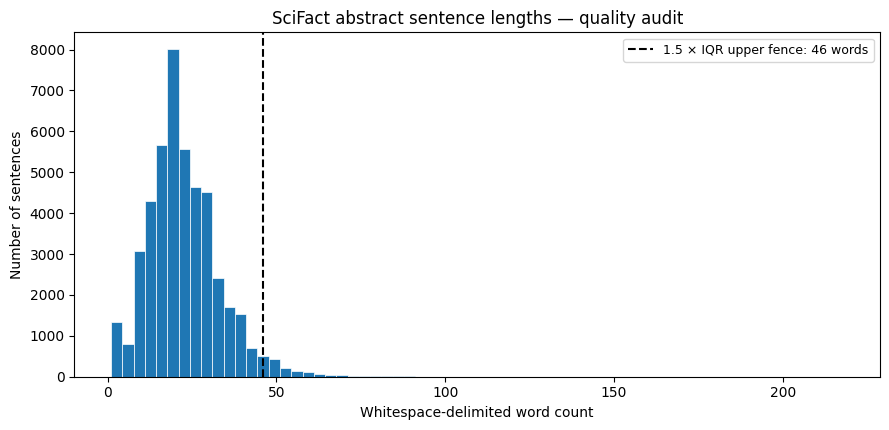

In [18]:
flag_counter = Counter()
for flags in sent_quality_df["flag_types"]:
    flag_counter.update(flags.split(";"))
flag_table = pd.DataFrame(
    [{"quality_flag": name, "sentence_occurrences": count} for name, count in flag_counter.most_common()]
)
display(flag_table)

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.hist(raw_lengths, bins=65, edgecolor="white", linewidth=0.5)
ax.axvline(upper_fence, color="black", linestyle="--", label=f"1.5 × IQR upper fence: {upper_fence:g} words")
ax.set_title("SciFact abstract sentence lengths — quality audit")
ax.set_xlabel("Whitespace-delimited word count")
ax.set_ylabel("Number of sentences")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "01_cleaning_sentence_length_distribution.png", dpi=180)
plt.show()


## 9. Export the processed data and audit artifacts

Outputs go to a **new** directory; the four raw JSONL files stay untouched. The cleaned JSONL files keep the **original SciFact field names**, so subsequent notebooks and code can load them with the same JSONL parser.

We export a compact machine-readable summary and flag tables so that data-quality decisions remain reproducible and can be explained in the Phase 1 README.

In [19]:
def save_jsonl(path, rows):
    with path.open("w", encoding="utf-8", newline="\n") as handle:
        for record in rows:
            handle.write(json.dumps(record, ensure_ascii=False) + "\n")

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

output_paths = {}
for file, rows in cleaned.items():
    output_path = PROCESSED_DIR / file.replace(".jsonl", "_clean.jsonl")
    save_jsonl(output_path, rows)
    output_paths[file] = output_path

sent_quality_df.to_csv(PROCESSED_DIR / "sentence_quality_flags.csv", index=False, encoding="utf-8")
doc_quality_df.to_csv(PROCESSED_DIR / "document_quality_flags.csv", index=False, encoding="utf-8")
pd.DataFrame(claim_duplicates, columns=[
    "split", "claim_id", "total_matching_claims", "matches_across_splits", "other_splits"
]).to_csv(PROCESSED_DIR / "duplicate_claim_flags.csv", index=False, encoding="utf-8")
changes_df.head(30).to_csv(PROCESSED_DIR / "text_normalization_examples.csv", index=False, encoding="utf-8")

summary = {
    "method": "NFC normalization and whitespace collapsing only; no record or sentence removal",
    "file_records": {f: len(rows) for f, rows in original.items()},
    "total_abstract_sentences": int(sum(len(doc["abstract"]) for doc in corpus)),
    "missing_or_invalid_required_fields": int(len(issues_df)),
    "initial_evidence_reference_errors": before_integrity["error_count"],
    "normalized_text_string_count": int(len(changes)),
    "duplicate_normalized_titles_excess": int(duplicate_title_excess),
    "repeated_abstract_sentences_excess": int(len(sentence_duplicates)),
    "duplicate_claim_text_overlaps": int(sum(len(v)-1 for v in claim_seen.values() if len(v)>1)),
    "sentence_length_IQR": {"q1": q1, "q3": q3, "upper_fence": upper_fence},
    "sentence_review_flag_counts": dict(flag_counter),
    "severe_repetition_doc_ids": [int(x) for x in severe_docs["doc_id"].tolist()],
    "raw_sha256": {f: digest(RAW_DIR / f) for f in SOURCE_FILES},
    "clean_sha256": {f: digest(path) for f, path in output_paths.items()},
}
with (PROCESSED_DIR / "cleaning_summary.json").open("w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2, ensure_ascii=False)

print("Saved cleaned JSONL:")
for path in output_paths.values():
    print(" -", path.relative_to(ROOT))
print("Saved audit summary and quality flags to data/processed/")
print("Saved audit figure:", (IMAGES_DIR / "01_cleaning_sentence_length_distribution.png").relative_to(ROOT))


Saved cleaned JSONL:
 - data\processed\corpus_clean.jsonl
 - data\processed\claims_train_clean.jsonl
 - data\processed\claims_dev_clean.jsonl
 - data\processed\claims_test_clean.jsonl
Saved audit summary and quality flags to data/processed/
Saved audit figure: images\01_cleaning_sentence_length_distribution.png


## 10. Verify outputs against the originals

This is a **mandatory verification cell**. We reload the files from disk and assert that:

- File record counts and all keys match the source.
- IDs and claim split membership are identical.
- Each abstract still has the same number and order of sentence positions.
- Every original `evidence` dictionary and `cited_doc_ids` list is unchanged.
- All reference and sentence-index integrity checks still pass.
- Every raw input file's SHA-256 hash is unchanged since loading.

No prediction model is trained or evaluated in this notebook.

In [20]:
reloaded = {source_file: load_jsonl(output_paths[source_file]) for source_file in SOURCE_FILES}

for source_file in SOURCE_FILES:
    old_rows, new_rows = original[source_file], reloaded[source_file]
    assert len(old_rows) == len(new_rows), source_file
    for old, new in zip(old_rows, new_rows):
        assert set(old) == set(new), source_file
        id_field = "doc_id" if source_file == "corpus.jsonl" else "id"
        assert old[id_field] == new[id_field]
        if source_file == "corpus.jsonl":
            assert len(old["abstract"]) == len(new["abstract"])
            assert old["structured"] == new["structured"]
        else:
            assert old.get("evidence") == new.get("evidence")
            assert old.get("cited_doc_ids") == new.get("cited_doc_ids")

assert all(digest(RAW_DIR / f) == summary["raw_sha256"][f] for f in SOURCE_FILES)
after_integrity = validate_structure_and_evidence(reloaded)
assert after_integrity["error_count"] == 0, after_integrity["examples"]
assert after_integrity["evidence_sets"] == before_integrity["evidence_sets"]
assert after_integrity["document_ids"] == before_integrity["document_ids"]
print("PASS: raw inputs unchanged, all cleaned files reloaded successfully.")
print("PASS: record IDs, split membership, sentence counts and indices preserved.")
print("PASS: evidence annotations, citations, and reference integrity preserved.")
print("PASS: cleaned dataset is ready for Phase 1 EDA.")


PASS: raw inputs unchanged, all cleaned files reloaded successfully.
PASS: record IDs, split membership, sentence counts and indices preserved.
PASS: evidence annotations, citations, and reference integrity preserved.
PASS: cleaned dataset is ready for Phase 1 EDA.


## 11. Findings and decisions to write in the Phase 1 README

**Observed from the actual dataset** (see live counts and tables above):

- Schema and evidence-link validation detected no missing required scientific text or broken evidence references.
- Duplicated sentence text and extremely repetitive abstracts were detected, but **not removed** because evidence labels depend on original sentence positions.
- Rare replacement characters were retained and flagged rather than guessing their original biomedical meaning.
- The only automatic corrections are Unicode NFC and whitespace consistency, producing processed copies in `data/processed/`.
- Empty evidence dictionaries do **not** automatically establish a `NOT_ENOUGH_INFO` stance label. Test claims have no gold evidence annotations by design.
- Duplicate claim texts across splits should be explicitly acknowledged before training/evaluation in Phase 2.

**Limitations:** This cleaning stage does not repair source OCR corruption, estimate model token counts, create negative claim-document labels, fit a scaler, or assess predictive performance. Those actions need separate, justified analysis and potentially different modeling decisions.

